## Xenium single-cell reannotation

In [1]:
import sys 
import os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")
import anndata as ad
#import hdf5plugin
import squidpy as sq
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt

import scvi
import cellcharter as cc
from lightning.pytorch import seed_everything

seed_everything(12345)
scvi.settings.seed = 12345

In [2]:
# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

%reload_ext autoreload

In [3]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100

In [4]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 80, color_map = 'RdPu', vector_friendly = True, format = 'pdf',  dpi_save=300)
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
#plt.style.use(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

/tmp/ipykernel_3326783/2901417997.py:5: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi = 80, color_map = 'RdPu', vector_friendly = True, format = 'pdf',  dpi_save=300)


In [5]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
results_path = os.path.join(repo_path, 'results')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

In [6]:
import seaborn as sns
thyAgeing_colors = pd.read_csv("/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing_colors.csv").set_index('color_name')['hex'].to_dict()
niche_enrich_palette = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)

In [7]:
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', vector_friendly = True, format = 'pdf',  dpi_save=300)

/tmp/ipykernel_3326783/722694596.py:1: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', vector_friendly = True, format = 'pdf',  dpi_save=300)


In [8]:
import hdf5plugin

## Load CellCharter results

In [9]:
xenium_adata = ad.read_h5ad(f'{data_path}/xenium/xenium_proseg/xenium_aging_labels.h5ad')
xenium_adata_sp = ad.read_h5ad(f'{data_path}/xenium/xenium_proseg/xenium_proseg_aging.h5ad')
xenium_adata.obsm['spatial'] = xenium_adata_sp.obsm['spatial'].copy()
xenium_adata.obsm['X_spatial'] = xenium_adata_sp.obsm['X_spatial'].copy()

In [10]:
xenium_adata_v1 = ad.read_h5ad(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/cellxgene/raw_data/ThyAge_xenium_adata_PaedAdult_filt_raw_2025-10-23.zarr')

In [11]:
donor2sample = {'U48': 'U48_FFPE1_01', 
                'U51': 'U51_FFPE1_01',
                'Z16': 'Z16_FFPE1_01', 
                'Z17': 'Z17_FFPE1_01',
                'A45': 'A45_FFPE1_01', 
                'A67': 'A67_FFPE1_01', 
                'A72': 'A72_FFPE1_01', 
                'A70': 'A70_FFPE2_01'}

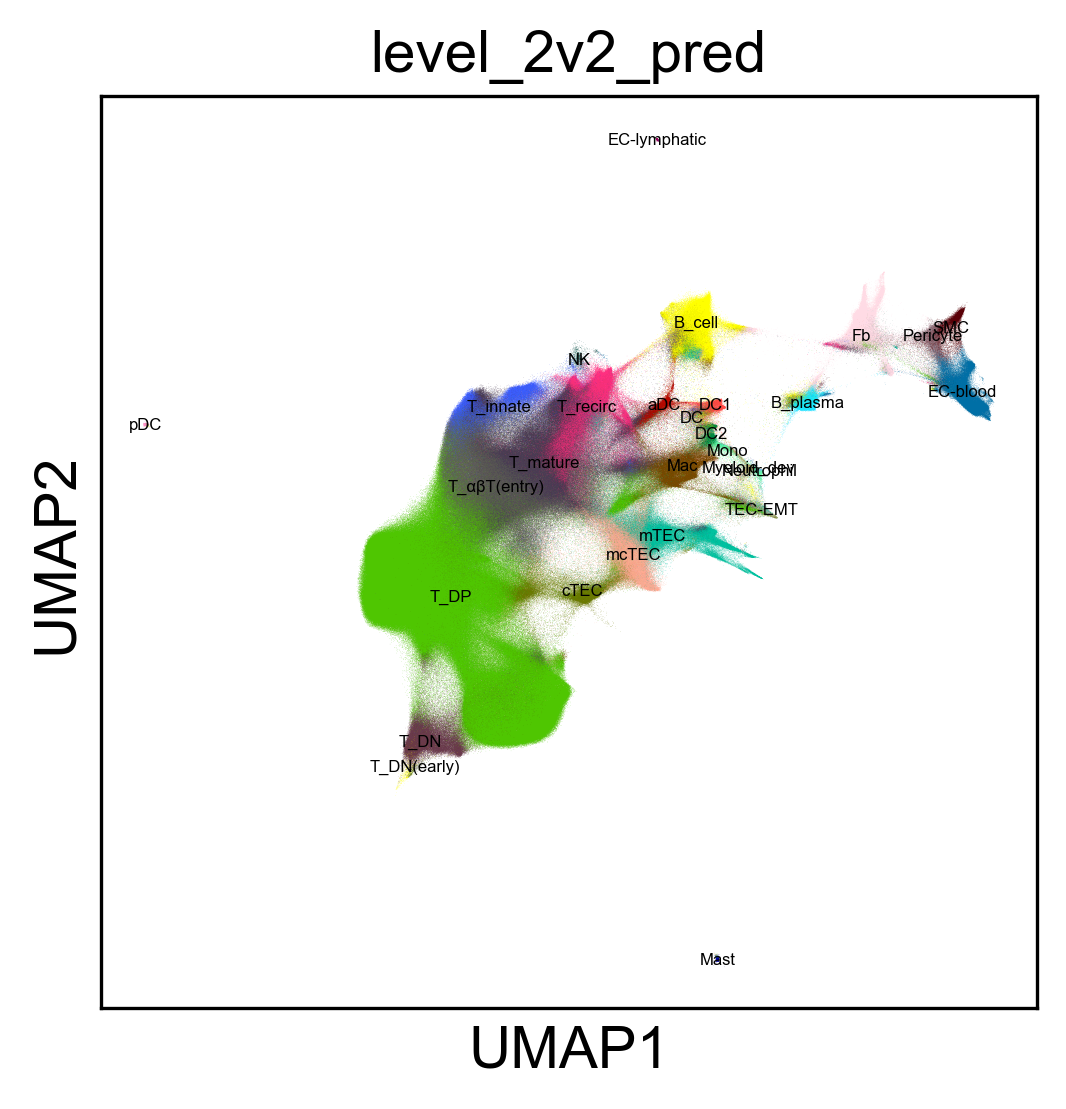

In [12]:
sc.pl.umap(xenium_adata, color = ['level_2v2_pred'], legend_loc = 'on data', legend_fontsize = 4)

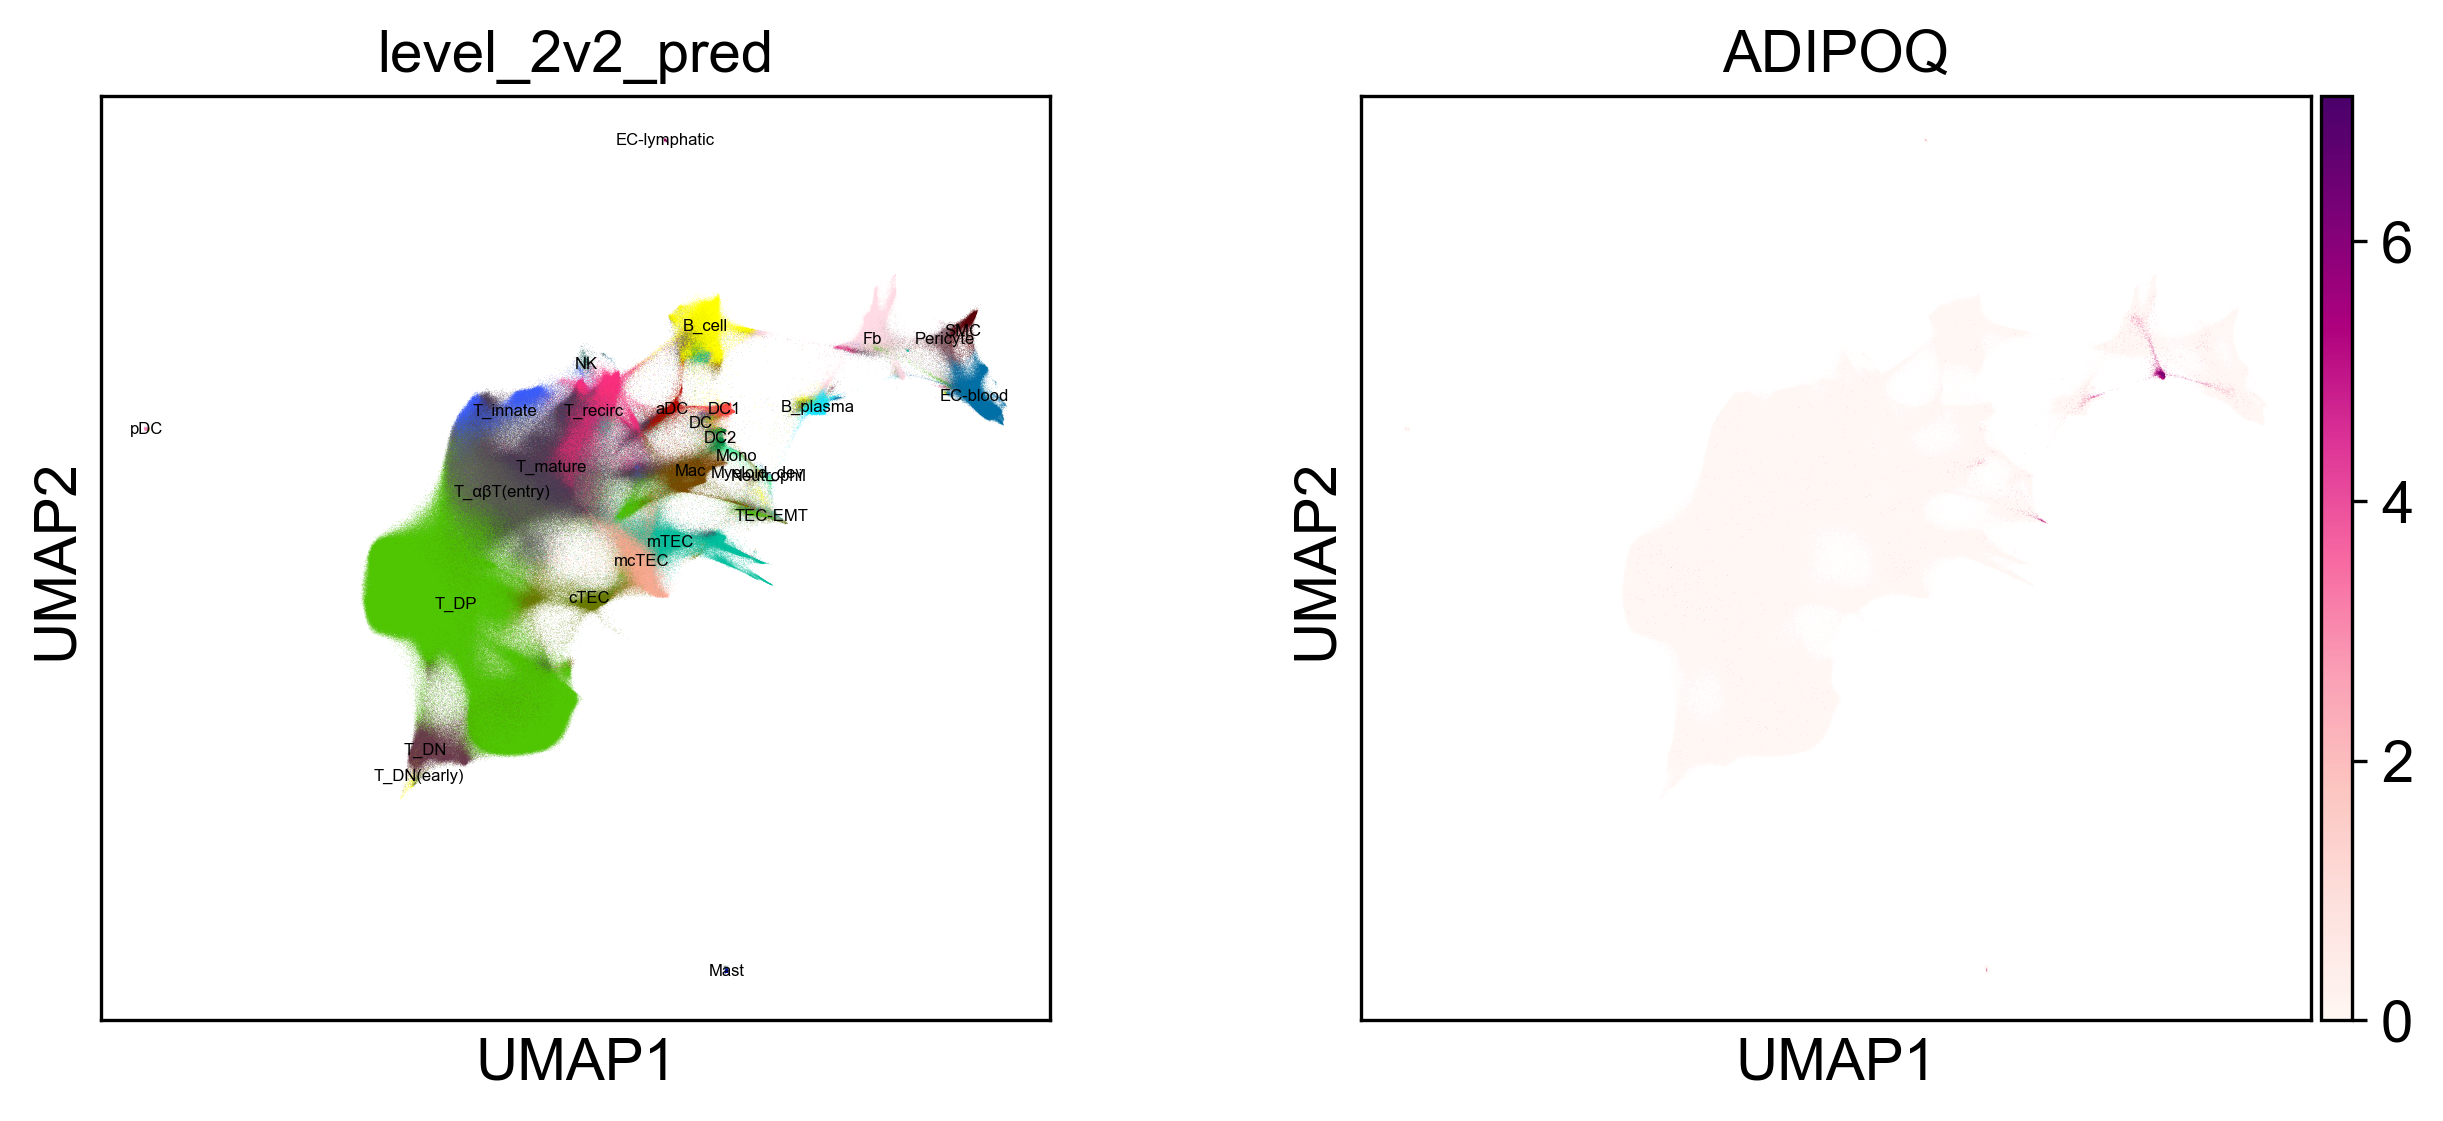

In [13]:
sc.pl.umap(xenium_adata, color = ['level_2v2_pred', 'ADIPOQ'], legend_loc = 'on data', legend_fontsize = 4)

In [14]:
xenium_adata_sp.obs['Sample_hr'] = xenium_adata_sp.obs['donor'].map(donor2sample)

In [15]:
xenium_adata_sp.obs['original_cell_barcode'] = xenium_adata_sp.obs['Sample_hr'].astype(str)+ '-'+ xenium_adata_sp.obs['original_cell_id'].astype(str)

In [16]:
one_to_one = (
    xenium_adata_sp.obs.groupby('original_cell_barcode')['sample_barcode'].nunique().max() == 1 and  # each id → one barcode
    xenium_adata_sp.obs.groupby('sample_barcode')['original_cell_barcode'].nunique().max() == 1      # each barcode → one id
)
one_to_one


np.True_

In [17]:
xenium_adata_sp.obs['proseg_barcode'] = 'xenium_' + xenium_adata_sp.obs['sample_barcode'].astype(str)

In [18]:
xenium_adata_sp.obs_names = xenium_adata_sp.obs['proseg_barcode'].copy()

In [19]:
xenium_adata_sp.obs.index.name = ''

In [20]:
xenium_adata_v2_obs = xenium_adata_sp.obs[['original_cell_barcode', 'proseg_barcode', 'Sample_hr', 'centroid_x', 'centroid_y', 'centroid_z',
       'component', 'volume', 'surface_area', 'scale', 'region']].copy()

In [21]:
xenium_adata.obs = xenium_adata.obs.merge(xenium_adata_v2_obs, how = 'left', left_index = True, right_index=True)

In [22]:
len(set(xenium_adata.obs['original_cell_barcode']).intersection(set(xenium_adata_v1.obs_names)))

1589786

In [23]:
xenium_adata_v1.obs['original_cell_barcode'] = xenium_adata_v1.obs_names.copy()

In [24]:
xenium_adata.obs_names = xenium_adata.obs['original_cell_barcode'].copy()

In [25]:
xenium_adata.obs.index.name = ''

In [26]:
xenium_adata.obs = xenium_adata.obs.merge(xenium_adata_v1.obs[['taa_l3', 'taa_l2_v2', 'niche_cellcharter6', 'niche_cellcharter3_v2']], how = 'left', left_index = True, right_index = True)

In [27]:
pd.crosstab(xenium_adata.obs['taa_l3'], xenium_adata.obs['level_3_pred'])

level_3_pred,B_GC-like,B_dev,B_mem,B_naive,B_plasma,DC1,DC2,EC-art,EC-cap,EC-cap_lipid,EC-lymphatic,EC-peri,EC-ven,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo,ILC,Mac,Mast,Mono,Myeloid_dev,NK,Neutrophil,Pericyte,SMC,TEC-EMT,TEC-mim,T_CD4,T_CD4_naive_recirc,T_CD4_recirc,T_CD8,T_CD8_recirc,T_CD8αα,T_DN,T_DN(early),T_DP,T_MAIT,T_Treg,T_Treg_recirc,T_αβT(entry),T_γδT,aDC,cTEC,mTECI,mTECII,mTECIII,mcTEC,pDC
taa_l3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Adipocyte,1,0,2,3,40,0,0,0,4,24,0,0,2,3344,27,155,6,389,0,11,0,0,0,0,0,4,4,38,17,0,1,1,1,2,0,1,0,12,0,1,1,3,0,0,0,0,0,0,2,0
B_GC-like,1383,4,10339,5763,112,22,3,1,6,0,0,0,5,1,0,0,15,18,0,15,4,3,1,0,0,2,2,9,11,53,50,3,23,35,22,1,0,73,1,262,28,118,0,252,1,245,77,50,37,7
B_dev,5,402,22,15,4,15,48,2,0,0,0,0,1,0,0,0,1,4,12,7,4,2,2,2,0,0,0,0,6,23,16,9,26,14,35,602,224,72,2,7,2,70,41,7,1,16,0,7,50,33
B_mem,617,13,29983,28653,349,118,79,13,151,1,0,0,70,3,13,11,146,512,1,693,30,15,6,1,0,29,30,39,52,240,287,46,201,269,87,15,0,406,3,410,88,574,6,327,23,1021,56,81,827,59
B_naive,31,12,1253,4541,31,10,6,3,74,0,0,0,22,3,2,4,19,91,2,29,6,1,2,0,0,9,3,2,7,106,58,2,88,15,10,15,0,333,0,94,15,215,1,54,0,17,4,1,13,7
B_plasma,46,11,1010,533,30715,38,0,10,231,10,1,5,25,36,12,67,45,963,2,183,9,1,8,1,0,37,28,69,7,113,126,33,144,96,52,21,0,1473,2,142,116,428,0,31,6,35,9,1,76,6
DC1,7,8,48,4,3,8485,17,1,2,0,0,0,2,1,0,2,1,10,0,36,0,4,1,0,0,0,2,0,0,3,6,3,8,11,10,3,0,100,0,8,13,59,0,180,10,14,0,11,22,7
DC2,4,16,4,0,0,63,2657,0,2,0,0,0,3,0,2,0,1,2,0,14,0,14,4,0,0,0,0,0,1,1,0,0,0,0,1,0,0,3,0,1,1,2,0,56,0,3,0,10,12,2
EC-art,1,0,1,0,1,0,0,4203,800,73,1,2,25,1,1,2,4,6,0,2,0,1,0,0,0,26,250,12,0,5,1,0,0,0,0,0,0,19,0,1,0,14,0,0,5,2,0,0,11,0


In [28]:
import scanpy as sc
import pandas as pd
import os
import numpy as np
import anndata
from sklearn.neighbors import KNeighborsTransformer

#These function were created by Lisa Sikemma

def weighted_knn_trainer(train_adata, train_adata_emb, n_neighbors=50):
    """Trains a weighted KNN classifier on ``train_adata``.
    Parameters
    ----------
    train_adata: :class:`~anndata.AnnData`
        Annotated dataset to be used to train KNN classifier with ``label_key`` as the target variable.
    train_adata_emb: str
        Name of the obsm layer to be used for calculation of neighbors. If set to "X", anndata.X will be
        used
    n_neighbors: int
        Number of nearest neighbors in KNN classifier.
    """
    print(
        f"Weighted KNN with n_neighbors = {n_neighbors} ... ",
        end="",
    )
    k_neighbors_transformer = KNeighborsTransformer(
        n_neighbors=n_neighbors,
        mode="distance",
        algorithm="brute",
        metric="euclidean",
        n_jobs=-1,
    )
    if train_adata_emb == "X":
        train_emb = train_adata.X
    elif train_adata_emb in train_adata.obsm.keys():
        train_emb = train_adata.obsm[train_adata_emb]
    else:
        raise ValueError(
            "train_adata_emb should be set to either 'X' or the name of the obsm layer to be used!"
        )
    k_neighbors_transformer.fit(train_emb)
    return k_neighbors_transformer    

def weighted_knn_transfer(
    query_adata,
    query_adata_emb,
    ref_adata_obs,
    label_keys,
    knn_model,
    threshold=1,
    pred_unknown=False,
    mode="package",
):
    """Annotates ``query_adata`` cells with an input trained weighted KNN classifier.
    Parameters
    ----------
    query_adata: :class:`~anndata.AnnData`
        Annotated dataset to be used to queryate KNN classifier. Embedding to be used
    query_adata_emb: str
        Name of the obsm layer to be used for label transfer. If set to "X",
        query_adata.X will be used
    ref_adata_obs: :class:`pd.DataFrame`
        obs of ref Anndata
    label_keys: str
        Names of the columns to be used as target variables (e.g. cell_type) in ``query_adata``.
    knn_model: :class:`~sklearn.neighbors._graph.KNeighborsTransformer`
        knn model trained on reference adata with weighted_knn_trainer function
    threshold: float
        Threshold of uncertainty used to annotating cells as "Unknown". cells with
        uncertainties higher than this value will be annotated as "Unknown".
        Set to 1 to keep all predictions. This enables one to later on play
        with thresholds.
    pred_unknown: bool
        ``False`` by default. Whether to annotate any cell as "unknown" or not.
        If `False`, ``threshold`` will not be used and each cell will be annotated
        with the label which is the most common in its ``n_neighbors`` nearest cells.
    mode: str
        Has to be one of "paper" or "package". If mode is set to "package",
        uncertainties will be 1 - P(pred_label), otherwise it will be 1 - P(true_label).
    """
    if not type(knn_model) == KNeighborsTransformer:
        raise ValueError(
            "knn_model should be of type sklearn.neighbors._graph.KNeighborsTransformer!"
        )

    if query_adata_emb == "X":
        query_emb = query_adata.X
    elif query_adata_emb in query_adata.obsm.keys():
        query_emb = query_adata.obsm[query_adata_emb]
    else:
        raise ValueError(
            "query_adata_emb should be set to either 'X' or the name of the obsm layer to be used!"
        )
    top_k_distances, top_k_indices = knn_model.kneighbors(X=query_emb)

    stds = np.std(top_k_distances, axis=1)
    stds = (2.0 / stds) ** 2
    stds = stds.reshape(-1, 1)

    top_k_distances_tilda = np.exp(-np.true_divide(top_k_distances, stds))

    weights = top_k_distances_tilda / np.sum(
        top_k_distances_tilda, axis=1, keepdims=True
    )
    cols = ref_adata_obs.columns[ref_adata_obs.columns.str.startswith(label_keys)]
    uncertainties = pd.DataFrame(columns=cols, index=query_adata.obs_names)
    pred_labels = pd.DataFrame(columns=cols, index=query_adata.obs_names)
    for i in range(len(weights)):
        for j in cols:
            y_train_labels = ref_adata_obs[j].values
            unique_labels = np.unique(y_train_labels[top_k_indices[i]])
            best_label, best_prob = None, 0.0
            for candidate_label in unique_labels:
                candidate_prob = weights[
                    i, y_train_labels[top_k_indices[i]] == candidate_label
                ].sum()
                if best_prob < candidate_prob:
                    best_prob = candidate_prob
                    best_label = candidate_label

            if pred_unknown:
                if best_prob >= threshold:
                    pred_label = best_label
                else:
                    pred_label = "Unknown"
            else:
                pred_label = best_label

            if mode == "package":
                uncertainties.iloc[i][j] = (max(1 - best_prob, 0))

            else:
                raise Exception("Inquery Mode!")

            pred_labels.iloc[i][j] = (pred_label)

    print("finished!")

    return pred_labels, uncertainties

In [29]:
xenium_v1_train = xenium_adata[~xenium_adata.obs['taa_l3'].isnull()]

In [30]:
xenium_v2_predict = xenium_adata[xenium_adata.obs['taa_l3'].isnull()]

In [31]:
knn_trainer_xenium_v1 = weighted_knn_trainer(train_adata = xenium_v1_train, train_adata_emb = 'X_scVI_shortlist_v1', 
                                         n_neighbors=30)

Weighted KNN with n_neighbors = 30 ... 

In [32]:
predict, uncert = weighted_knn_transfer(
    query_adata = xenium_v2_predict,
    query_adata_emb = 'X_scVI_shortlist_v1',
    ref_adata_obs = xenium_v1_train.obs,
    label_keys = ('taa_l3', 'taa_l2_v2', 'niche_cellcharter6', 'niche_cellcharter3_v2'),
    knn_model = knn_trainer_xenium_v1,
    threshold=1,
    pred_unknown=False,
    mode="package",
)

/tmp/ipykernel_3326783/2539319877.py:130: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  uncertainties.iloc[i][j] = (max(1 - best_prob, 0))
/tmp/ipykernel_3326783/2539319877.py:135: FutureWarning: ChainedAssignmentError: behaviour will change

finished!


In [33]:
predict.columns = [f'knn_xen_pred-{i}' for i in ['taa_l3', 'taa_l2_v2', 'niche_cellcharter6', 'niche_cellcharter3_v2']]
uncert.columns = [f'knn_xen_uncert-{i}' for i in ['taa_l3', 'taa_l2_v2', 'niche_cellcharter6', 'niche_cellcharter3_v2']]    

In [34]:
knn_pred_df = pd.concat([predict, uncert],axis = 1)

In [69]:
knn_pred_df.to_csv(f'{data_path}/xenium/ThyAge_xenium_annos_v1-v2_knn_predict_donors_{today}.csv')

In [41]:
knn_pred_df

,knn_xen_pred-taa_l3,knn_xen_pred-taa_l2_v2,knn_xen_pred-niche_cellcharter6,knn_xen_pred-niche_cellcharter3_v2,knn_xen_uncert-taa_l3,knn_xen_uncert-taa_l2_v2,knn_xen_uncert-niche_cellcharter6,knn_xen_uncert-niche_cellcharter3_v2
,,,,,,,,
A45_FFPE1_01-fmoejggm-1,TEC-EMT,TEC-EMT,Capsule/PVS,Cortex,0.333324,0.333324,0.666685,0.533363
A45_FFPE1_01-fmobdbfp-1,TEC-EMT,TEC-EMT,Capsule/PVS,Cortex,0.599944,0.599944,0.633299,0.466632
A45_FFPE1_01-fmobafof-1,TEC-EMT,TEC-EMT,Capsule/PVS,Cortex,0.23332,0.23332,0.566738,0.466772
A45_FFPE1_01-aabjmbbb-1,TEC-EMT,TEC-EMT,Capsule/PVS,Cortex,0.466736,0.466736,0.700037,0.466628
A45_FFPE1_01-fndclnhh-1,Fb-perilo,Fb,Adipose,PVS,0.233333,0.033331,0.500003,0.233331
...,...,...,...,...,...,...,...,...
A67_FFPE1_01-edmboikj-1,Mac,Mac,mcTEC-rich,Medulla,0.133316,0.133316,0.433345,0.433345
A67_FFPE1_01-lmackihk-1,Mac,Mac,Capsule/PVS,Cortex,0.266656,0.266656,0.533339,0.400014
A67_FFPE1_01-lmdcfdfi-1,EC-cap,EC-blood,Adipose,PVS,0.40001,0.033332,0.166678,0.166678


In [45]:
xenium_adata.obs = xenium_adata.obs.merge(knn_pred_df, how = 'left', left_index = True, right_index = True).copy()

In [47]:
xenium_adata.obs['knn_xen_pred-taa_l3']


A45_FFPE1_01-fmoejggm-1       TEC-EMT
A45_FFPE1_01-fmobdbfp-1       TEC-EMT
A45_FFPE1_01-fmobafof-1       TEC-EMT
A45_FFPE1_01-aabjmbbb-1       TEC-EMT
A45_FFPE1_01-fndclnhh-1     Fb-perilo
                              ...    
A67_FFPE1_01-lmadipff-1           NaN
A67_FFPE1_01-lmafjgjk-1           NaN
A67_FFPE1_01-lmdcfdfi-1        EC-cap
A67_FFPE1_01-lmdboohf-1     Fb-perilo
A67_FFPE1_01-lmaeeehg-1    Fb-interlo
Name: knn_xen_pred-taa_l3, Length: 3531679, dtype: object

In [49]:
xenium_adata.obs.loc[xenium_adata.obs['taa_l3'].isnull(), 'donor'].value_counts()

donor
U48    1032758
U51     501863
A72     141740
A45      89285
A67      62608
Z17      44836
A70      43069
Z16      25734
Name: count, dtype: int64

In [50]:
xenium_adata.obs.loc[xenium_adata.obs['taa_l3'].isnull(),'taa_l3_comb'] = xenium_adata.obs.loc[xenium_adata.obs['taa_l3'].isnull(), 'knn_xen_pred-taa_l3'].copy()

xenium_adata.obs.loc[~xenium_adata.obs['taa_l3'].isnull(),'taa_l3_comb'] = xenium_adata.obs.loc[~xenium_adata.obs['taa_l3'].isnull(), 'taa_l3'].copy()

In [56]:
xenium_adata.obs.loc[xenium_adata.obs['taa_l2_v2'].isnull(),'taa_l2_comb'] = xenium_adata.obs.loc[xenium_adata.obs['taa_l2_v2'].isnull(), 'knn_xen_pred-taa_l2_v2'].copy()

xenium_adata.obs.loc[~xenium_adata.obs['taa_l2_v2'].isnull(),'taa_l2_comb'] = xenium_adata.obs.loc[~xenium_adata.obs['taa_l2_v2'].isnull(), 'taa_l2_v2'].copy()

In [61]:
xenium_adata.obs.loc[xenium_adata.obs['niche_cellcharter6'].isnull(),'niche_cellcharter6_comb'] = xenium_adata.obs.loc[xenium_adata.obs['niche_cellcharter6'].isnull(), 'knn_xen_pred-niche_cellcharter6'].copy()

xenium_adata.obs.loc[~xenium_adata.obs['niche_cellcharter6'].isnull(),'niche_cellcharter6_comb'] = xenium_adata.obs.loc[~xenium_adata.obs['niche_cellcharter6'].isnull(), 'niche_cellcharter6'].copy()

In [64]:
xenium_adata.obs.columns

Index(['sample_ID', 'donor', 'chemistry_simple', 'cells_spatial',
       '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1',
       'level_0_pred', 'level_0_prob', 'level_1_pred', 'level_1_prob',
       'level_2_pred', 'level_2_prob', 'level_3_pred', 'level_3_prob',
       'level_4_pred', 'level_4_prob', 'level_5_pred', 'level_5_prob',
       'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob',
       'original_cell_barcode', 'proseg_barcode', 'Sample_hr', 'centroid_x',
       'centroid_y', 'centroid_z', 'component', 'volume', 'surface_area',
       'scale', 'region', 'taa_l3', 'taa_l2_v2', 'niche_cellcharter6',
       'niche_cellcharter3_v2', 'knn_xen_pred-taa_l3',
       'knn_xen_pred-taa_l2_v2', 'knn_xen_pred-niche_cellcharter6',
       'knn_xen_pred-niche_cellcharter3_v2', 'knn_xen_uncert-taa_l3',
       'knn_xen_uncert-taa_l2_v2', 'knn_xen_uncert-niche_cellcharter6',
       'knn_xen_uncert-niche_cellcharter3_v2', 'taa_l3_comb', 'taa_l2_comb',
       '

In [66]:
xenium_adata.obs.loc[xenium_adata.obs['niche_cellcharter3_v2'].isnull(),'niche_cellcharter3_v2_comb'] = xenium_adata.obs.loc[xenium_adata.obs['niche_cellcharter3_v2'].isnull(), 'knn_xen_pred-niche_cellcharter3_v2'].copy()

xenium_adata.obs.loc[~xenium_adata.obs['niche_cellcharter3_v2'].isnull(),'niche_cellcharter3_v2_comb'] = xenium_adata.obs.loc[~xenium_adata.obs['niche_cellcharter3_v2'].isnull(), 'niche_cellcharter3_v2'].copy()

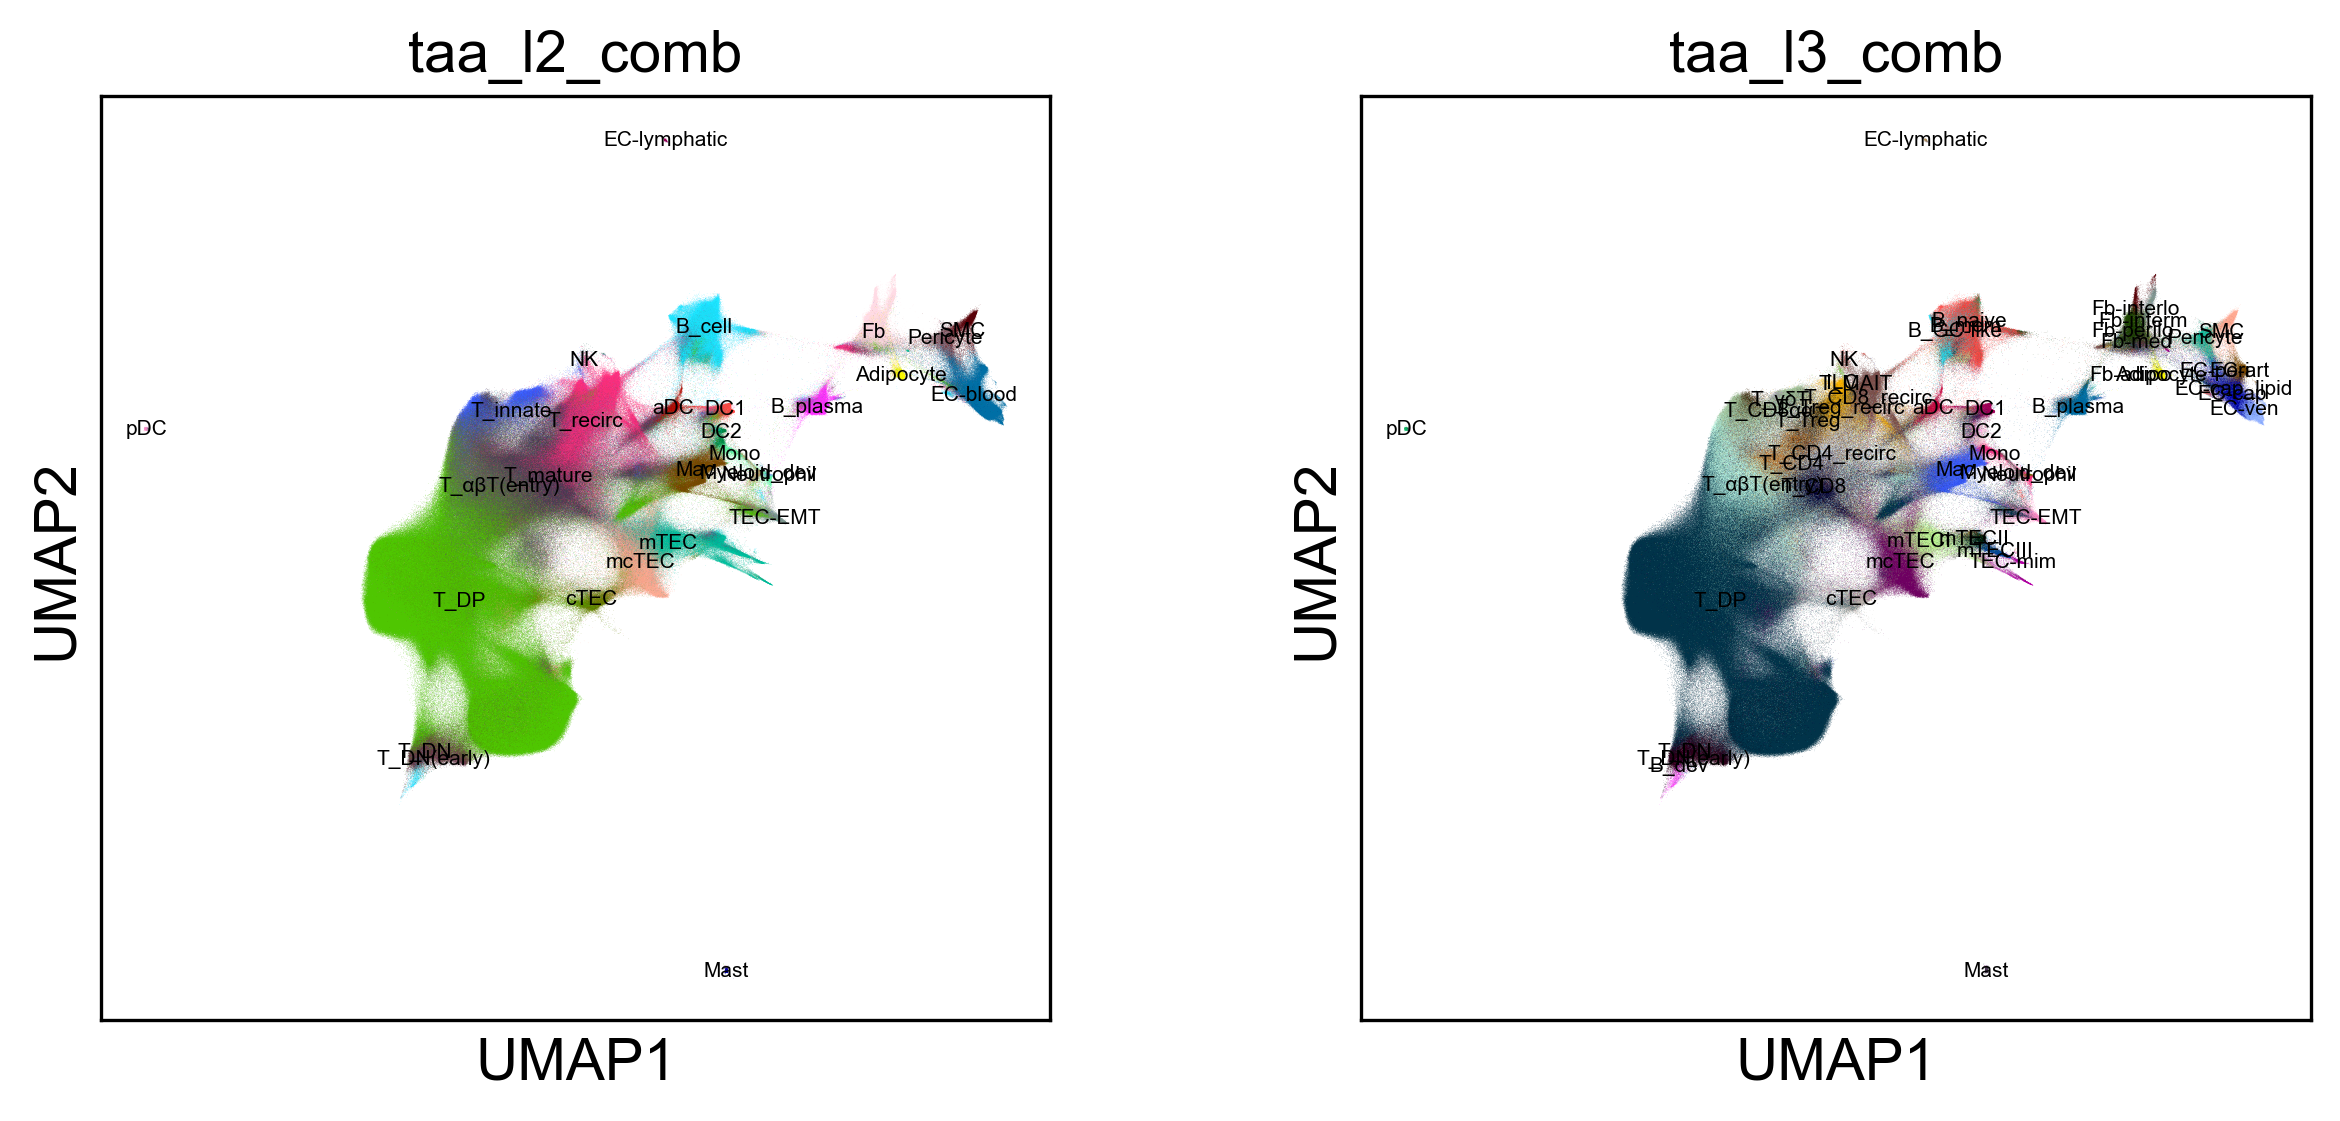

In [59]:
sc.pl.umap(xenium_adata, color = ['taa_l2_comb', 'taa_l3_comb'], legend_loc = 'on data', legend_fontsize = 5)

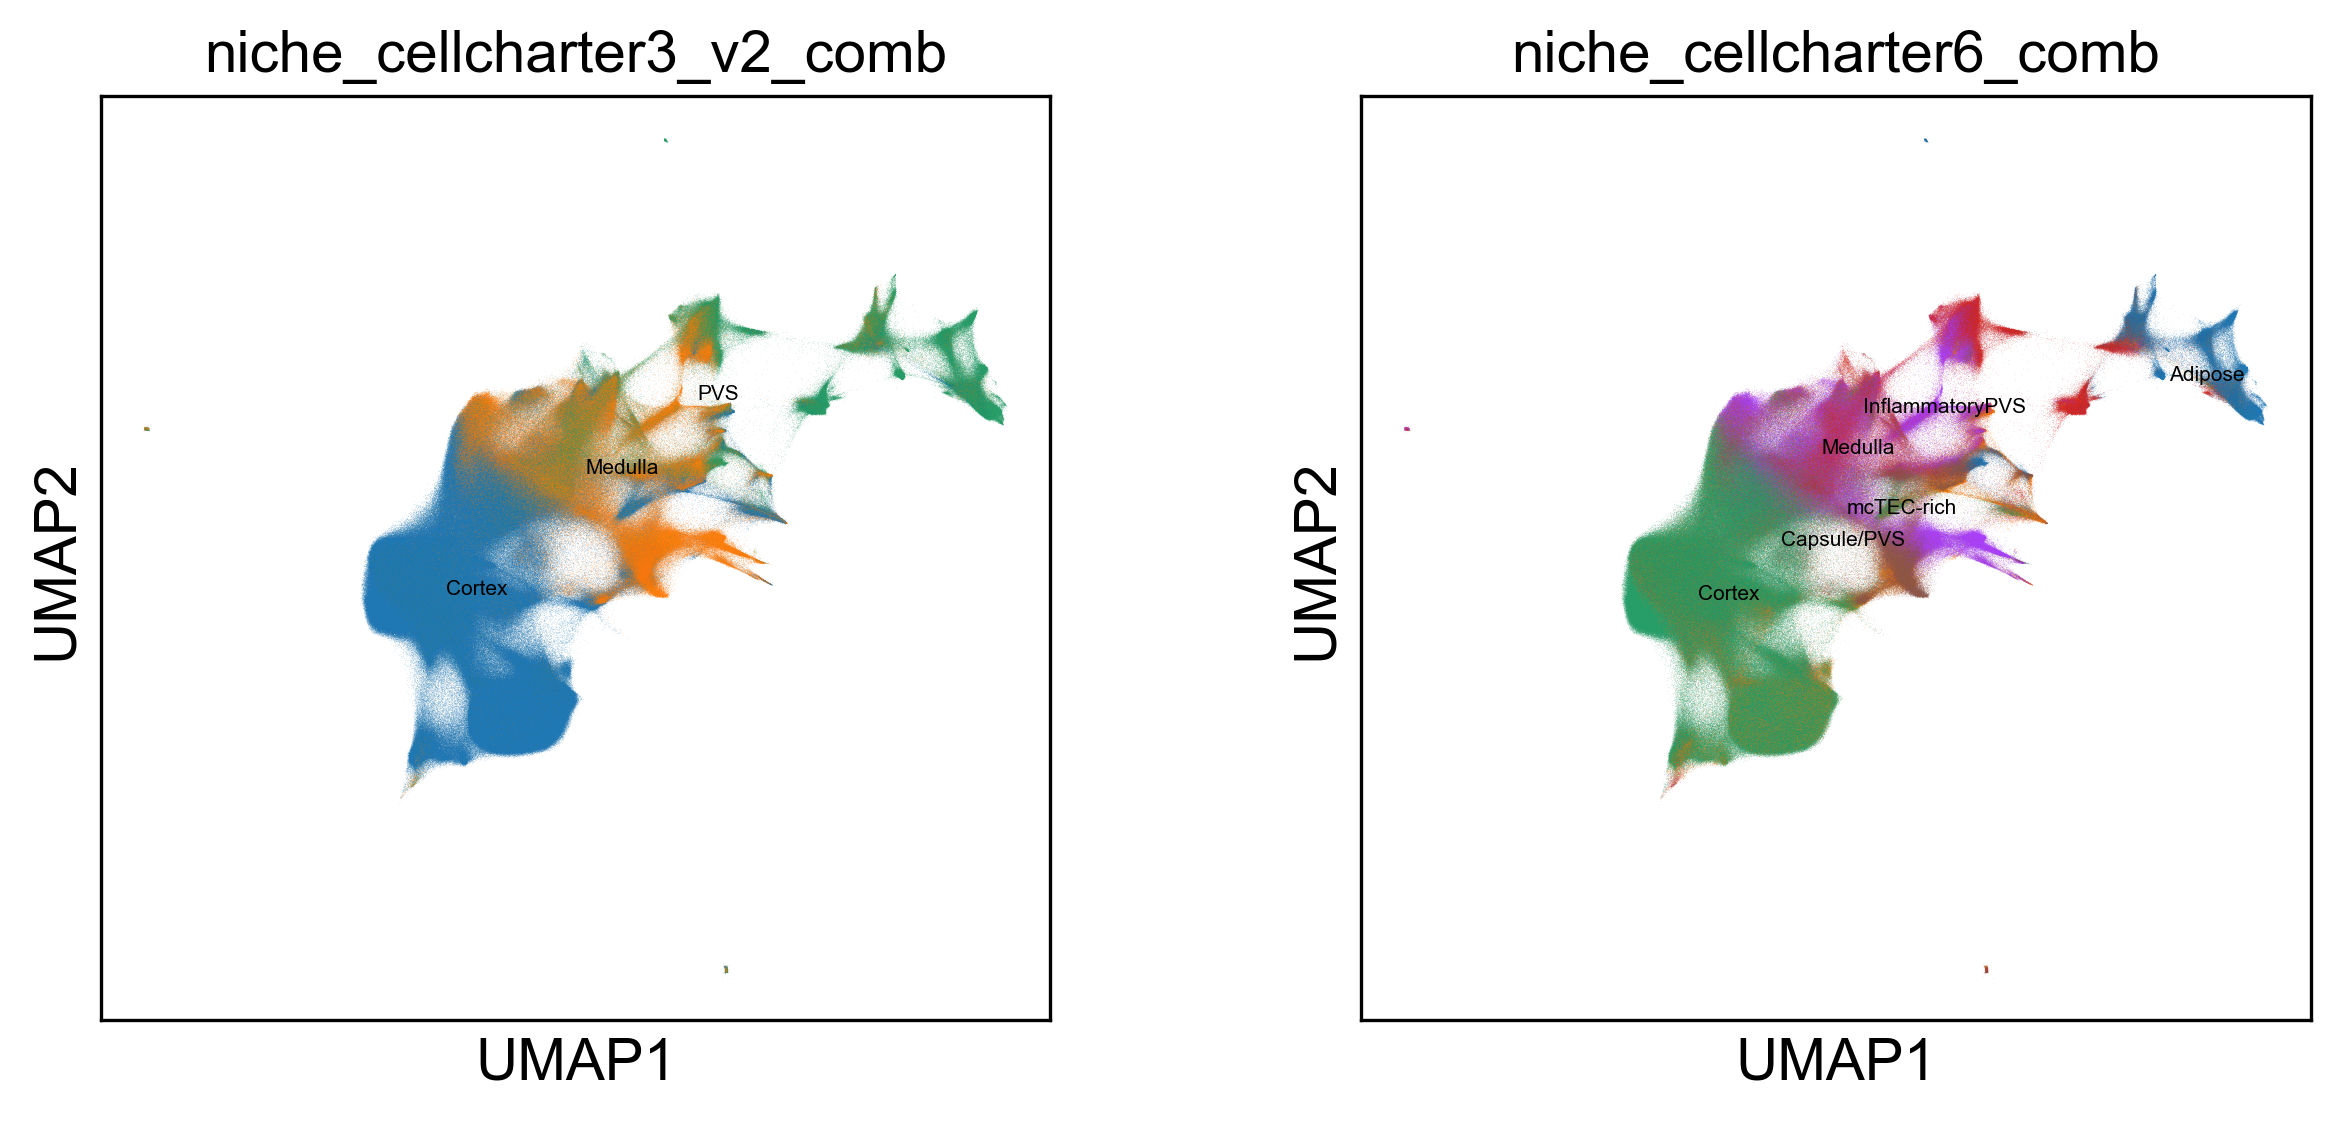

In [67]:
sc.pl.umap(xenium_adata, color = ['niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb'], legend_loc = 'on data', legend_fontsize = 5)

In [68]:
xenium_adata.obs.to_csv(f'{data_path}/xenium/ThyAge_xenium_annos_v1-v2_predict_{today}.csv')

In [77]:
xenium_adata.obs.loc[xenium_adata.obs['taa_l3_comb'] == 'Fb-adipo', 'donor'].value_counts()

donor
A72    109
A70     54
A67     22
Z17      3
A45      0
U48      0
U51      0
Z16      0
Name: count, dtype: int64

In [77]:
xenium_adata.obs.loc[xenium_adata.obs['taa_l3_comb'] == 'Fb-adipo', 'donor'].value_counts()

donor
A72    109
A70     54
A67     22
Z17      3
A45      0
U48      0
U51      0
Z16      0
Name: count, dtype: int64

In [39]:
f'{data_path}/xenium/ThyAge_xenium_annos_v1-v2_predict_{today}.csv'

'/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv'

In [38]:
os.path.isfile(f'{data_path}/xenium/ThyAge_xenium_annos_v1-v2_predict_{today}.csv')

True

## Load single-cell embedding

In [13]:
import pickle 
with open (f'{data_path}/xenium/ThyAge_scell2xenium_integ_2025-04-09_embed.pickle', 'rb') as file:
    scell2xen_embed = pickle.load(file)

In [14]:
xenium_adata.obsm['X_scVI'] = scell2xen_embed['X_scVI'].copy()
xenium_adata.obsm['X_umap'] = scell2xen_embed['X_umap'].copy()
xenium_adata.obsp = scell2xen_embed['obsp'].copy()

## Load Cellcharter niches

In [ ]:
clusters = ['cluster_cellcharter', 'cluster_cellcharter6', 'cluster_cellcharter10']
xenium_adata.obs[clusters] = pd.read_csv(f'{data_path}/xenium/ThyAge_xenium_adata_paed+adult_CellCharter_clusters.csv', index_col = 0).reindex(xenium_adata.obs_names)